<a href="https://colab.research.google.com/github/arjunk-15/Healthcare-Operations-Dashboard/blob/main/Notebooks/Healthcare_Operations_Dashboard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from datetime import datetime, timedelta
from google.colab import files

What is hospital configuration?

*It means setting fixed information such as department names, bed capacity, date range, and number of patients. We'll reuse these values across our datasets to keep them consistent.*

In [4]:
departments = [
    "Emergency",
    "Cardiology",
    "Orthopedics",
    "Neurology",
    "General Medicine"
]

bed_capacity = {
    "Emergency" : 30,
    "Cardiology" : 54,
    "Orthopedics" : 20,
    "Neurology" : 54,
    "General Medicine" : 20
}

start_date = datetime(2025, 1, 1)
end_date = datetime(2025, 12, 31)

total_patients = 5000
total_staff = 150

random.seed(42)
np.random.seed(42)

print("Departments:", departments)
print("Total beds:", sum(bed_capacity.values()))
print("Total patients:", total_patients)
print("Total staff:", total_staff)

Departments: ['Emergency', 'Cardiology', 'Orthopedics', 'Neurology', 'General Medicine']
Total beds: 178
Total patients: 5000
Total staff: 150


In [2]:
uploaded = files.upload()
df = pd.read_csv("Admissions.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Records:")
display(df.head())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Saving Admissions.csv to Admissions.csv
Dataset Shape: (5000, 7)

First 5 Records:


,Admission_ID,Patient_ID,Department,Admission_Date,Discharge_Date,Admission_Type,Length_of_Stay_Days
0,ADM00001,P00205,Orthopedics,2025-01-01,2025-01-03,Elective,2
1,ADM00002,P00218,Cardiology,2025-01-01,2025-01-04,Elective,3
2,ADM00003,P00423,Neurology,2025-01-01,2025-01-04,Emergency,3
3,ADM00004,P00790,Neurology,2025-01-01,2025-01-07,Emergency,6
4,ADM00005,P01414,General Medicine,2025-01-01,2025-01-05,Emergency,4



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Admission_ID         5000 non-null   object
 1   Patient_ID           5000 non-null   object
 2   Department           5000 non-null   object
 3   Admission_Date       5000 non-null   object
 4   Discharge_Date       5000 non-null   object
 5   Admission_Type       5000 non-null   object
 6   Length_of_Stay_Days  5000 non-null   int64 
dtypes: int64(1), object(6)
memory usage: 273.6+ KB

Missing Values:
Admission_ID           0
Patient_ID             0
Department             0
Admission_Date         0
Discharge_Date         0
Admission_Type         0
Length_of_Stay_Days    0
dtype: int64


Currently, *Pandas reads Admission_Date* and *Discharge_Date* as object (text).

To perform monthly admissions analysis, calculate hospital stays, and work with dates correctly, we should convert them to datetime.

In [3]:
df["Admission_Date"] = pd.to_datetime(df["Admission_Date"])
df["Discharge_Date"] = pd.to_datetime(df["Discharge_Date"])

In [4]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate Admission IDs:", df["Admission_ID"].duplicated().sum())

Duplicate rows: 0
Duplicate Admission IDs: 0


In [6]:
df["Calculated_LOS"] = (
    df["Discharge_Date"] - df["Admission_Date"]
).dt.days

print("LOS mismatches:",
      (df["Calculated_LOS"] != df["Length_of_Stay_Days"]).sum())

print("Negative LOS:", (df["Calculated_LOS"] < 0).sum())
print("Zero-day stays:", (df["Calculated_LOS"] == 0).sum())

LOS mismatches: 0
Negative LOS: 0
Zero-day stays: 0


The dataset has no issues in the checks we've performed. We should still validate department names and date ranges before considering it fully cleaned.

In [7]:
print(df["Department"].unique())
print(df["Admission_Type"].value_counts())

['Orthopedics' 'Cardiology' 'Neurology' 'General Medicine' 'Emergency']
Admission_Type
Emergency    2229
Elective     1785
Urgent        986
Name: count, dtype: int64


In [8]:
print("First admission:", df["Admission_Date"].min())
print("Last admission:", df["Admission_Date"].max())

First admission: 2025-01-01 00:00:00
Last admission: 2025-12-20 00:00:00


In [9]:
df.drop(columns=["Calculated_LOS"], inplace=True)

**To download the cleaned CSV:**

In [10]:
df.to_csv("Admissions_Cleaned.csv", index=False)
files.download("Admissions_Cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
files.upload()
bed_df = pd.read_csv("Bed_Occupancy.csv")

print("Dataset Shape:", bed_df.shape)
display(bed_df.head())

bed_df.info()

print("\nMissing Values:")
print(bed_df.isnull().sum())

print("\nDuplicate Rows:")
print(bed_df.duplicated().sum())

Saving Bed_Occupancy.csv to Bed_Occupancy.csv
Dataset Shape: (1825, 5)


,Snapshot_Date,Department,Total_Beds,Occupied_Beds,Available_Beds
0,2025-01-01,Emergency,30,0,30
1,2025-01-01,Cardiology,54,2,52
2,2025-01-01,Orthopedics,20,1,19
3,2025-01-01,Neurology,54,7,47
4,2025-01-01,General Medicine,20,4,16


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1825 entries, 0 to 1824
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Snapshot_Date   1825 non-null   object
 1   Department      1825 non-null   object
 2   Total_Beds      1825 non-null   int64 
 3   Occupied_Beds   1825 non-null   int64 
 4   Available_Beds  1825 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 71.4+ KB

Missing Values:
Snapshot_Date     0
Department        0
Total_Beds        0
Occupied_Beds     0
Available_Beds    0
dtype: int64

Duplicate Rows:
0


In [14]:
bed_df["Snapshot_Date"] = pd.to_datetime(bed_df["Snapshot_Date"])

print(
    "Duplicate department-date records:",
    bed_df.duplicated(
        subset=["Snapshot_Date", "Department"]
    ).sum()
)

bed_df["Calculated_Total"] = (
    bed_df["Occupied_Beds"] + bed_df["Available_Beds"]
)

print(
    "Bed count mismatches:",
    (bed_df["Calculated_Total"] != bed_df["Total_Beds"]).sum()
)

Duplicate department-date records: 0
Bed count mismatches: 0


In [13]:
print(
    "Negative occupied beds:",
    (bed_df["Occupied_Beds"] < 0).sum()
)

print(
    "Over-capacity records:",
    (bed_df["Occupied_Beds"] > bed_df["Total_Beds"]).sum()
)

print(
    bed_df.groupby("Department")["Total_Beds"].unique()
)

bed_df["Occupancy_Rate"] = (
    bed_df["Occupied_Beds"] / bed_df["Total_Beds"]
) * 100

display(bed_df.head())

Negative occupied beds: 0
Over-capacity records: 0
Department
Cardiology          [54]
Emergency           [30]
General Medicine    [20]
Neurology           [54]
Orthopedics         [20]
Name: Total_Beds, dtype: object


,Snapshot_Date,Department,Total_Beds,Occupied_Beds,Available_Beds,Occupancy_Rate
0,2025-01-01,Emergency,30,0,30,0.000000
1,2025-01-01,Cardiology,54,2,52,3.703704
2,2025-01-01,Orthopedics,20,1,19,5.000000
3,2025-01-01,Neurology,54,7,47,12.962963
4,2025-01-01,General Medicine,20,4,16,20.000000


In [15]:
print("Duplicate department-date records:",
      bed_df.duplicated(
          subset=["Snapshot_Date", "Department"]
      ).sum())

print("Bed count mismatches:",
      (bed_df["Occupied_Beds"] + bed_df["Available_Beds"]
       != bed_df["Total_Beds"]).sum())

print("Number of unique dates:",
      bed_df["Snapshot_Date"].nunique())

bed_df["Occupancy_Rate"] = bed_df["Occupancy_Rate"].round(2)
bed_df.drop(columns=["Calculated_Total"], errors="ignore", inplace=True)
bed_df.to_csv("Bed_Occupancy_Cleaned.csv", index=False)

files.download("Bed_Occupancy_Cleaned.csv")

Duplicate department-date records: 0
Bed count mismatches: 0
Number of unique dates: 365


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
uploaded = files.upload()
wait_df = pd.read_csv("Patient_Waiting_Time.csv")

print("Dataset Shape:", wait_df.shape)

display(wait_df.head())

wait_df.info()

print("\nMissing Values:")
print(wait_df.isnull().sum())

print("\nDuplicate Rows:")
print(wait_df.duplicated().sum())

Saving Patient_Waiting_Time.csv to Patient_Waiting_Time.csv
Dataset Shape: (5000, 7)


,Admission_ID,Patient_ID,Department,Check_In_Time,Consultation_Time,Wait_Time_Minutes,Shift
0,ADM00001,P00205,Orthopedics,2025-01-01 19:06:00,2025-01-01 19:28:00,22,Evening
1,ADM00002,P00218,Cardiology,2025-01-01 17:29:00,2025-01-01 18:19:00,50,Evening
2,ADM00003,P00423,Neurology,2025-01-01 19:29:00,2025-01-01 19:37:00,8,Evening
3,ADM00004,P00790,Neurology,2025-01-01 19:05:00,2025-01-01 19:27:00,22,Evening
4,ADM00005,P01414,General Medicine,2025-01-01 13:37:00,2025-01-01 14:47:00,70,Morning


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Admission_ID       5000 non-null   object
 1   Patient_ID         5000 non-null   object
 2   Department         5000 non-null   object
 3   Check_In_Time      5000 non-null   object
 4   Consultation_Time  5000 non-null   object
 5   Wait_Time_Minutes  5000 non-null   int64 
 6   Shift              5000 non-null   object
dtypes: int64(1), object(6)
memory usage: 273.6+ KB

Missing Values:
Admission_ID         0
Patient_ID           0
Department           0
Check_In_Time        0
Consultation_Time    0
Wait_Time_Minutes    0
Shift                0
dtype: int64

Duplicate Rows:
0


*Initial inspection passed*

Total records
1,825


Missing values
0


Duplicate rows
0

In [17]:
print(wait_df.columns.tolist())
display(wait_df.head())


['Admission_ID', 'Patient_ID', 'Department', 'Check_In_Time', 'Consultation_Time', 'Wait_Time_Minutes', 'Shift']


,Admission_ID,Patient_ID,Department,Check_In_Time,Consultation_Time,Wait_Time_Minutes,Shift
0,ADM00001,P00205,Orthopedics,2025-01-01 19:06:00,2025-01-01 19:28:00,22,Evening
1,ADM00002,P00218,Cardiology,2025-01-01 17:29:00,2025-01-01 18:19:00,50,Evening
2,ADM00003,P00423,Neurology,2025-01-01 19:29:00,2025-01-01 19:37:00,8,Evening
3,ADM00004,P00790,Neurology,2025-01-01 19:05:00,2025-01-01 19:27:00,22,Evening
4,ADM00005,P01414,General Medicine,2025-01-01 13:37:00,2025-01-01 14:47:00,70,Morning


In [18]:
print("Missing Values:")
print(wait_df.isnull().sum())

print("\nDuplicate Rows:", wait_df.duplicated().sum())

Missing Values:
Admission_ID         0
Patient_ID           0
Department           0
Check_In_Time        0
Consultation_Time    0
Wait_Time_Minutes    0
Shift                0
dtype: int64

Duplicate Rows: 0


In [20]:
print("Unique Patients:", wait_df["Patient_ID"].nunique())

print("\nDepartments:")
print(wait_df["Department"].value_counts())
print(wait_df.columns.tolist())

Unique Patients: 4400

Departments:
Department
Cardiology          1427
Neurology           1320
Emergency            938
General Medicine     669
Orthopedics          646
Name: count, dtype: int64
['Admission_ID', 'Patient_ID', 'Department', 'Check_In_Time', 'Consultation_Time', 'Wait_Time_Minutes', 'Shift']


In [24]:
wait_df["Check_In_Time"] = pd.to_datetime(wait_df["Check_In_Time"])
wait_df["Consultation_Time"] = pd.to_datetime(
    wait_df["Consultation_Time"])

wait_df["Calculated_Wait_Minutes"] = (
    wait_df["Consultation_Time"] - wait_df["Check_In_Time"]
).dt.total_seconds() / 60

print("Negative waiting times:",
      (wait_df["Calculated_Wait_Minutes"] < 0).sum())

print("Zero waiting times:",
      (wait_df["Calculated_Wait_Minutes"] == 0).sum())

print("Maximum waiting time:",
      wait_df["Calculated_Wait_Minutes"].max())

print("Average waiting time:",
      wait_df["Calculated_Wait_Minutes"].mean())

wait_df.groupby("Department")["Calculated_Wait_Minutes"].mean().round(2)

Negative waiting times: 0
Zero waiting times: 0
Maximum waiting time: 139.0
Average waiting time: 47.0324


,Calculated_Wait_Minutes
Department,
Cardiology,40.25
Emergency,76.36
General Medicine,40.55
Neurology,39.68
Orthopedics,41.15


In [25]:
print("Missing values:")
print(wait_df.isnull().sum())

print("Duplicate rows:", wait_df.duplicated().sum())

print("Negative waiting times:",
      (wait_df["Calculated_Wait_Minutes"] < 0).sum())

print("Missing calculated waiting times:",
      wait_df["Calculated_Wait_Minutes"].isna().sum())

Missing values:
Admission_ID               0
Patient_ID                 0
Department                 0
Check_In_Time              0
Consultation_Time          0
Wait_Time_Minutes          0
Shift                      0
Calculated_Wait_Minutes    0
dtype: int64
Duplicate rows: 0
Negative waiting times: 0
Missing calculated waiting times: 0


*Occupied Beds + Available Beds = Total Beds*


In [26]:
wait_df.rename(
    columns={"Calculated_Wait_Minutes": "Waiting_Time_Minutes"},
    inplace=True
)

wait_df["Waiting_Time_Minutes"] = (
    wait_df["Waiting_Time_Minutes"].round(2)
)

In [27]:
wait_df.to_csv(
    "Patient_Waiting_Time_Cleaned.csv",
    index=False
)

files.download("Patient_Waiting_Time_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
uploaded = files.upload()
staff_df = pd.read_csv("Staff_Details.csv")

print("Dataset Shape:", staff_df.shape)

display(staff_df.head())

staff_df.info()

print("\nMissing Values:")
print(staff_df.isnull().sum())

print("\nDuplicate Rows:")
print(staff_df.duplicated().sum())

Saving Staff_Details.csv to Staff_Details.csv
Dataset Shape: (150, 4)


,Staff_ID,Staff_Name,Department,Role
0,S0001,Synthetic Staff 001,Emergency,Nurse
1,S0002,Synthetic Staff 002,Cardiology,Technician
2,S0003,Synthetic Staff 003,Orthopedics,Nurse
3,S0004,Synthetic Staff 004,Neurology,Nurse
4,S0005,Synthetic Staff 005,General Medicine,Technician


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Staff_ID    150 non-null    object
 1   Staff_Name  150 non-null    object
 2   Department  150 non-null    object
 3   Role        150 non-null    object
dtypes: object(4)
memory usage: 4.8+ KB

Missing Values:
Staff_ID      0
Staff_Name    0
Department    0
Role          0
dtype: int64

Duplicate Rows:
0


In [29]:
print("Staff by Department:")
print(staff_df["Department"].value_counts())

print("\nStaff by Role:")
print(staff_df["Role"].value_counts())

print("Duplicate Staff IDs:",
      staff_df["Staff_ID"].duplicated().sum())

print("Total Unique Staff:",
      staff_df["Staff_ID"].nunique())

Staff by Department:
Department
Emergency           30
Cardiology          30
Orthopedics         30
Neurology           30
General Medicine    30
Name: count, dtype: int64

Staff by Role:
Role
Nurse         93
Technician    24
Doctor        24
Support        9
Name: count, dtype: int64
Duplicate Staff IDs: 0
Total Unique Staff: 150


In [30]:
print("Duplicate Staff IDs:",
      staff_df["Staff_ID"].duplicated().sum())

print("Unique Staff:",
      staff_df["Staff_ID"].nunique())

print("\nStaff by Department:")
print(staff_df["Department"].value_counts())

print("\nStaff by Role:")
print(staff_df["Role"].value_counts())

Duplicate Staff IDs: 0
Unique Staff: 150

Staff by Department:
Department
Emergency           30
Cardiology          30
Orthopedics         30
Neurology           30
General Medicine    30
Name: count, dtype: int64

Staff by Role:
Role
Nurse         93
Technician    24
Doctor        24
Support        9
Name: count, dtype: int64


In [34]:
departments = [
    "Emergency",
    "Cardiology",
    "Orthopedics",
    "Neurology",
    "General Medicine"
]

In [35]:
print("Invalid Departments:",
      (~staff_df["Department"].isin(departments)).sum())

staff_df.to_csv("Staff_Details_Cleaned.csv", index=False)
files.download("Staff_Details_Cleaned.csv")

Invalid Departments: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
uploaded = files.upload()
schedule_df = pd.read_csv("Staff_Schedule.csv")

print("Dataset Shape:", schedule_df.shape)

display(schedule_df.head())

schedule_df.info()

print("\nMissing Values:")
print(schedule_df.isnull().sum())

print("\nDuplicate Rows:")
print(schedule_df.duplicated().sum())

Saving Staff_Schedule.csv to Staff_Schedule.csv
Dataset Shape: (32808, 4)


,Staff_ID,Shift_Date,Shift,Availability
0,S0001,2025-01-02,Evening,Available
1,S0001,2025-01-06,Night,Available
2,S0001,2025-01-07,Evening,Available
3,S0001,2025-01-08,Morning,Available
4,S0001,2025-01-12,Morning,Available


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32808 entries, 0 to 32807
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Staff_ID      32808 non-null  object
 1   Shift_Date    32808 non-null  object
 2   Shift         32808 non-null  object
 3   Availability  32808 non-null  object
dtypes: object(4)
memory usage: 1.0+ MB

Missing Values:
Staff_ID        0
Shift_Date      0
Shift           0
Availability    0
dtype: int64

Duplicate Rows:
0


In [39]:
schedule_df["Shift_Date"] = pd.to_datetime(
    schedule_df["Shift_Date"]
)

print("Shift Types:")
print(schedule_df["Shift"].value_counts())

print("\nAvailability:")
print(schedule_df["Availability"].value_counts())

print("\nUnique Staff:")
print(schedule_df["Staff_ID"].nunique())

invalid_staff = ~schedule_df["Staff_ID"].isin(
    staff_df["Staff_ID"]
)

print("Invalid Staff IDs:", invalid_staff.sum())

Shift Types:
Shift
Morning    11054
Evening    10930
Night      10824
Name: count, dtype: int64

Availability:
Availability
Available    30884
Absent        1924
Name: count, dtype: int64

Unique Staff:
150
Invalid Staff IDs: 0


In [40]:
invalid_staff = ~schedule_df["Staff_ID"].isin(
    staff_df["Staff_ID"]
)

print("Invalid Staff IDs:", invalid_staff.sum())
print(
    "Duplicate Staff-Date-Shift:",
    schedule_df.duplicated(
        subset=["Staff_ID", "Shift_Date", "Shift"]
    ).sum()
)

Invalid Staff IDs: 0
Duplicate Staff-Date-Shift: 0


In [41]:
print("First Shift:", schedule_df["Shift_Date"].min())
print("Last Shift:", schedule_df["Shift_Date"].max())

valid_shifts = ["Morning", "Evening", "Night"]

print(
    "Invalid Shifts:",
    (~schedule_df["Shift"].isin(valid_shifts)).sum()
)
daily_shifts = schedule_df.groupby(
    ["Staff_ID", "Shift_Date"]
).size()

print(
    "Staff-days with multiple shifts:",
    (daily_shifts > 1).sum()
)

First Shift: 2025-01-01 00:00:00
Last Shift: 2025-12-31 00:00:00
Invalid Shifts: 0
Staff-days with multiple shifts: 0


In [42]:
schedule_df.to_csv(
    "Staff_Schedule_Cleaned.csv",
    index=False
)

files.download("Staff_Schedule_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
uploaded = files.upload()

staff_df = pd.read_csv("Staff_Details_Cleaned.csv")
schedule_df = pd.read_csv("Staff_Schedule_Cleaned.csv")

Saving Staff_Details_Cleaned.csv to Staff_Details_Cleaned.csv
Saving Staff_Schedule_Cleaned.csv to Staff_Schedule_Cleaned.csv


In [4]:
staff_schedule_df = pd.merge(
    schedule_df,
    staff_df,
    on="Staff_ID",
    how="left",
    validate="many_to_one"
)

print("Merged Shape:", staff_schedule_df.shape)
display(staff_schedule_df.head())

Merged Shape: (32808, 7)


,Staff_ID,Shift_Date,Shift,Availability,Staff_Name,Department,Role
0,S0001,2025-01-02,Evening,Available,Synthetic Staff 001,Emergency,Nurse
1,S0001,2025-01-06,Night,Available,Synthetic Staff 001,Emergency,Nurse
2,S0001,2025-01-07,Evening,Available,Synthetic Staff 001,Emergency,Nurse
3,S0001,2025-01-08,Morning,Available,Synthetic Staff 001,Emergency,Nurse
4,S0001,2025-01-12,Morning,Available,Synthetic Staff 001,Emergency,Nurse


In [5]:
print("Original schedule rows:", len(schedule_df))
print("Merged rows:", len(staff_schedule_df))

print("Missing departments:",
      staff_schedule_df["Department"].isnull().sum())

print("Missing roles:",
      staff_schedule_df["Role"].isnull().sum())

Original schedule rows: 32808
Merged rows: 32808
Missing departments: 0
Missing roles: 0


In [6]:
available_staff_df = staff_schedule_df[
    staff_schedule_df["Availability"] == "Available"
]

print("Available staff-shift records:", len(available_staff_df))

Available staff-shift records: 30884


In [7]:
staff_availability_df = (
    available_staff_df
    .groupby(["Shift_Date", "Department", "Shift"])
    ["Staff_ID"]
    .nunique()
    .reset_index(name="Available_Staff")
)

display(staff_availability_df.head())
print("Shape:", staff_availability_df.shape)

,Shift_Date,Department,Shift,Available_Staff
0,2025-01-01,Cardiology,Evening,8
1,2025-01-01,Cardiology,Morning,11
2,2025-01-01,Cardiology,Night,5
3,2025-01-01,Emergency,Evening,3
4,2025-01-01,Emergency,Morning,6


Shape: (5466, 4)


In [8]:
avg_staff = (
    staff_availability_df
    .groupby("Department")["Available_Staff"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

print(avg_staff)

Department
Cardiology          5.67
General Medicine    5.66
Neurology           5.66
Emergency           5.64
Orthopedics         5.62
Name: Available_Staff, dtype: float64


In [52]:
staff_schedule_df.to_csv(
    "Staff_Schedule_Merged.csv",
    index=False
)

staff_availability_df.to_csv(
    "Staff_Availability_Summary.csv",
    index=False
)

In [11]:
uploaded = files.upload()
admissions_df = pd.read_csv("Admissions_Cleaned.csv")
wait_df = pd.read_csv("Patient_Waiting_Time_Cleaned.csv")

print("Admissions:", admissions_df.shape)
print("Waiting:", wait_df.shape)

print("\nAdmissions columns:")
print(admissions_df.columns.tolist())

print("\nWaiting columns:")
print(wait_df.columns.tolist())

Saving Admissions_Cleaned.csv to Admissions_Cleaned.csv
Saving Patient_Waiting_Time_Cleaned.csv to Patient_Waiting_Time_Cleaned.csv
Admissions: (5000, 7)
Waiting: (5000, 8)

Admissions columns:
['Admission_ID', 'Patient_ID', 'Department', 'Admission_Date', 'Discharge_Date', 'Admission_Type', 'Length_of_Stay_Days']

Waiting columns:
['Admission_ID', 'Patient_ID', 'Department', 'Check_In_Time', 'Consultation_Time', 'Wait_Time_Minutes', 'Shift', 'Waiting_Time_Minutes']


In [12]:
print("Admissions unique patients:",
      admissions_df["Patient_ID"].nunique())

print("Waiting unique patients:",
      wait_df["Patient_ID"].nunique())

print("Repeated Patient IDs in admissions:",
      admissions_df["Patient_ID"].duplicated().sum())

print("Repeated Patient IDs in waiting:",
      wait_df["Patient_ID"].duplicated().sum())

print("Admission_ID in waiting dataset:",
      "Admission_ID" in wait_df.columns)

Admissions unique patients: 4400
Waiting unique patients: 4400
Repeated Patient IDs in admissions: 600
Repeated Patient IDs in waiting: 600
Admission_ID in waiting dataset: True


In [19]:
print("Duplicate Admission IDs in admissions:",
      admissions_df["Admission_ID"].duplicated().sum())

print("Duplicate Admission IDs in waiting:",
      wait_df["Admission_ID"].duplicated().sum())

print("Waiting IDs missing from admissions:",
      (~wait_df["Admission_ID"].isin(
          admissions_df["Admission_ID"]
      )).sum())

patient_merged_df = pd.merge(
    admissions_df,
    wait_df,
    on="Admission_ID",
    how="left",
    suffixes=("_Admission", "_Waiting"),
    validate="one_to_one",
    indicator=True
)

print("Merged Shape:", patient_merged_df.shape)

print("\nMerge Status:")
print(patient_merged_df["_merge"].value_counts())

display(patient_merged_df.head())

Duplicate Admission IDs in admissions: 0
Duplicate Admission IDs in waiting: 0
Waiting IDs missing from admissions: 0
Merged Shape: (5000, 15)

Merge Status:
_merge
both          5000
left_only        0
right_only       0
Name: count, dtype: int64


,Admission_ID,Patient_ID_Admission,Department_Admission,Admission_Date,Discharge_Date,Admission_Type,Length_of_Stay_Days,Patient_ID_Waiting,Department_Waiting,Check_In_Time,Consultation_Time,Wait_Time_Minutes,Shift,Waiting_Time_Minutes,_merge
0,ADM00001,P00205,Orthopedics,2025-01-01,2025-01-03,Elective,2,P00205,Orthopedics,2025-01-01 19:06:00,2025-01-01 19:28:00,22,Evening,22.0,both
1,ADM00002,P00218,Cardiology,2025-01-01,2025-01-04,Elective,3,P00218,Cardiology,2025-01-01 17:29:00,2025-01-01 18:19:00,50,Evening,50.0,both
2,ADM00003,P00423,Neurology,2025-01-01,2025-01-04,Emergency,3,P00423,Neurology,2025-01-01 19:29:00,2025-01-01 19:37:00,8,Evening,8.0,both
3,ADM00004,P00790,Neurology,2025-01-01,2025-01-07,Emergency,6,P00790,Neurology,2025-01-01 19:05:00,2025-01-01 19:27:00,22,Evening,22.0,both
4,ADM00005,P01414,General Medicine,2025-01-01,2025-01-05,Emergency,4,P01414,General Medicine,2025-01-01 13:37:00,2025-01-01 14:47:00,70,Morning,70.0,both


In [20]:
print("Patient ID mismatches:",
      (patient_merged_df["Patient_ID_Admission"] !=
       patient_merged_df["Patient_ID_Waiting"]).sum())

print("Department mismatches:",
      (patient_merged_df["Department_Admission"] !=
       patient_merged_df["Department_Waiting"]).sum())

Patient ID mismatches: 0
Department mismatches: 0


In [21]:
print(
    "Waiting time mismatches:",
    (
        patient_merged_df["Wait_Time_Minutes"]
        != patient_merged_df["Waiting_Time_Minutes"]
    ).sum()
)
patient_merged_df["Admission_Date"] = pd.to_datetime(
    patient_merged_df["Admission_Date"]
)

patient_merged_df["Check_In_Time"] = pd.to_datetime(
    patient_merged_df["Check_In_Time"]
)

patient_merged_df["Consultation_Time"] = pd.to_datetime(
    patient_merged_df["Consultation_Time"]
)

print(
    "Admission/check-in date mismatches:",
    (
        patient_merged_df["Admission_Date"].dt.date
        != patient_merged_df["Check_In_Time"].dt.date
    ).sum()
)

print(
    "Consultations before check-in:",
    (
        patient_merged_df["Consultation_Time"]
        < patient_merged_df["Check_In_Time"]
    ).sum()
)

Waiting time mismatches: 0
Admission/check-in date mismatches: 0
Consultations before check-in: 0


In [22]:
patient_merged_df.drop(
    columns=[
        "Patient_ID_Waiting",
        "Department_Waiting",
        "Wait_Time_Minutes",
        "_merge"
    ],
    inplace=True
)

patient_merged_df.rename(
    columns={
        "Patient_ID_Admission": "Patient_ID",
        "Department_Admission": "Department"
    },
    inplace=True
)

display(patient_merged_df.head())

,Admission_ID,Patient_ID,Department,Admission_Date,Discharge_Date,Admission_Type,Length_of_Stay_Days,Check_In_Time,Consultation_Time,Shift,Waiting_Time_Minutes
0,ADM00001,P00205,Orthopedics,2025-01-01,2025-01-03,Elective,2,2025-01-01 19:06:00,2025-01-01 19:28:00,Evening,22.0
1,ADM00002,P00218,Cardiology,2025-01-01,2025-01-04,Elective,3,2025-01-01 17:29:00,2025-01-01 18:19:00,Evening,50.0
2,ADM00003,P00423,Neurology,2025-01-01,2025-01-04,Emergency,3,2025-01-01 19:29:00,2025-01-01 19:37:00,Evening,8.0
3,ADM00004,P00790,Neurology,2025-01-01,2025-01-07,Emergency,6,2025-01-01 19:05:00,2025-01-01 19:27:00,Evening,22.0
4,ADM00005,P01414,General Medicine,2025-01-01,2025-01-05,Emergency,4,2025-01-01 13:37:00,2025-01-01 14:47:00,Morning,70.0


In [23]:
patient_merged_df.to_csv(
    "Patient_Operations_Integrated.csv",
    index=False
)

files.download("Patient_Operations_Integrated.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Now we need to check whether our daily bed occupancy figures are consistent with the admission and discharge records.

Why is this important?

*Suppose a department reports 20 occupied beds, but the admission records suggest 35 patients are staying there.*

That could indicate a data inconsistency. We should identify it before building the dashboard.

In [24]:
uploaded = files.upload()

patient_df = pd.read_csv("Patient_Operations_Integrated.csv")
bed_df = pd.read_csv("Bed_Occupancy_Cleaned.csv")

patient_df["Admission_Date"] = pd.to_datetime(patient_df["Admission_Date"])
patient_df["Discharge_Date"] = pd.to_datetime(patient_df["Discharge_Date"])
bed_df["Snapshot_Date"] = pd.to_datetime(bed_df["Snapshot_Date"])

Saving Bed_Occupancy_Cleaned.csv to Bed_Occupancy_Cleaned.csv
Saving Patient_Operations_Integrated.csv to Patient_Operations_Integrated (1).csv


In [26]:
print("Department Bed Capacities:")

print(
    bed_df.groupby("Department")["Total_Beds"].first()
)

print("\nTotal Hospital Beds:",
      bed_df.groupby("Department")["Total_Beds"].first().sum())

print(
    "Over-capacity records:",
    (bed_df["Occupied_Beds"] > bed_df["Total_Beds"]).sum()
)

print(
    "Negative available beds:",
    (bed_df["Available_Beds"] < 0).sum()
)

daily_admissions = (
    patient_df.groupby(["Admission_Date", "Department"])
    .size()
    .reset_index(name="Daily_Admissions")
)

display(daily_admissions.head())

Department Bed Capacities:
Department
Cardiology          54
Emergency           30
General Medicine    20
Neurology           54
Orthopedics         20
Name: Total_Beds, dtype: int64

Total Hospital Beds: 178
Over-capacity records: 0
Negative available beds: 0


,Admission_Date,Department,Daily_Admissions
0,2025-01-01,Cardiology,2
1,2025-01-01,General Medicine,4
2,2025-01-01,Neurology,7
3,2025-01-01,Orthopedics,1
4,2025-01-02,Cardiology,3


Now merge daily admissions with bed occupancy:

In [27]:
daily_operations = pd.merge(
    bed_df,
    daily_admissions,
    left_on=["Snapshot_Date", "Department"],
    right_on=["Admission_Date", "Department"],
    how="left",
    validate="one_to_one"
)

daily_operations["Daily_Admissions"] = (
    daily_operations["Daily_Admissions"].fillna(0).astype(int)
)

display(daily_operations.head())

,Snapshot_Date,Department,Total_Beds,Occupied_Beds,Available_Beds,Occupancy_Rate,Admission_Date,Daily_Admissions
0,2025-01-01,Emergency,30,0,30,0.00,NaT,0
1,2025-01-01,Cardiology,54,2,52,3.70,2025-01-01,2
2,2025-01-01,Orthopedics,20,1,19,5.00,2025-01-01,1
3,2025-01-01,Neurology,54,7,47,12.96,2025-01-01,7
4,2025-01-01,General Medicine,20,4,16,20.00,2025-01-01,4


A patient is considered occupying a bed on dates when:

*Admission_Date <= Snapshot_Date < Discharge_Date*

We'll treat the discharge date as the day the bed becomes available. This is a simplified daily census assumption.

In [28]:
daily_census = []

for date in bed_df["Snapshot_Date"].unique():
    active = patient_df[
        (patient_df["Admission_Date"] <= date) &
        (patient_df["Discharge_Date"] > date)
    ]

    counts = active.groupby("Department").size()

    for department in bed_df["Department"].unique():
        daily_census.append({
            "Snapshot_Date": date,
            "Department": department,
            "Calculated_Occupied_Beds": counts.get(department, 0)
        })

census_df = pd.DataFrame(daily_census)

display(census_df.head())
print("Shape:", census_df.shape)

,Snapshot_Date,Department,Calculated_Occupied_Beds
0,2025-01-01,Emergency,0
1,2025-01-01,Cardiology,2
2,2025-01-01,Orthopedics,1
3,2025-01-01,Neurology,7
4,2025-01-01,General Medicine,4


Shape: (1825, 3)


In [29]:
occupancy_validation = pd.merge(
    bed_df,
    census_df,
    on=["Snapshot_Date", "Department"],
    how="left",
    validate="one_to_one"
)

occupancy_validation["Occupancy_Difference"] = (
    occupancy_validation["Occupied_Beds"]
    - occupancy_validation["Calculated_Occupied_Beds"]
)

print(
    "Matching records:",
    (occupancy_validation["Occupancy_Difference"] == 0).sum()
)

print(
    "Mismatching records:",
    (occupancy_validation["Occupancy_Difference"] != 0).sum()
)

print(
    "Maximum absolute difference:",
    occupancy_validation["Occupancy_Difference"].abs().max()
)

display(occupancy_validation.head())

Matching records: 1825
Mismatching records: 0
Maximum absolute difference: 0


,Snapshot_Date,Department,Total_Beds,Occupied_Beds,Available_Beds,Occupancy_Rate,Calculated_Occupied_Beds,Occupancy_Difference
0,2025-01-01,Emergency,30,0,30,0.00,0,0
1,2025-01-01,Cardiology,54,2,52,3.70,2,0
2,2025-01-01,Orthopedics,20,1,19,5.00,1,0
3,2025-01-01,Neurology,54,7,47,12.96,7,0
4,2025-01-01,General Medicine,20,4,16,20.00,4,0


In [30]:
department_validation = (
    occupancy_validation
    .groupby("Department")["Occupancy_Difference"]
    .agg(["mean", "min", "max"])
    .round(2)
)

display(department_validation)

,mean,min,max
Department,,,
Cardiology,0.0,0,0
Emergency,0.0,0,0
General Medicine,0.0,0,0
Neurology,0.0,0,0
Orthopedics,0.0,0,0


**Export Daily Operations**

In [31]:
daily_operations = daily_operations.merge(
    census_df,
    on=["Snapshot_Date", "Department"],
    how="left",
    validate="one_to_one"
)

daily_operations.to_csv(
    "Daily_Hospital_Operations.csv",
    index=False
)

files.download("Daily_Hospital_Operations.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
patient_df["Admission_Month"] = (
    patient_df["Admission_Date"].dt.to_period("M")
)

monthly_admissions = (
    patient_df.groupby("Admission_Month")
    .size()
    .reset_index(name="Total_Admissions")
)

monthly_admissions["Admission_Month"] = (
    monthly_admissions["Admission_Month"].astype(str)
)

display(monthly_admissions)

,Admission_Month,Total_Admissions
0,2025-01,395
1,2025-02,445
2,2025-03,494
3,2025-04,419
4,2025-05,425
5,2025-06,480
6,2025-07,506
7,2025-08,503
8,2025-09,462
9,2025-10,511


**Visualize Monthly Admissions**

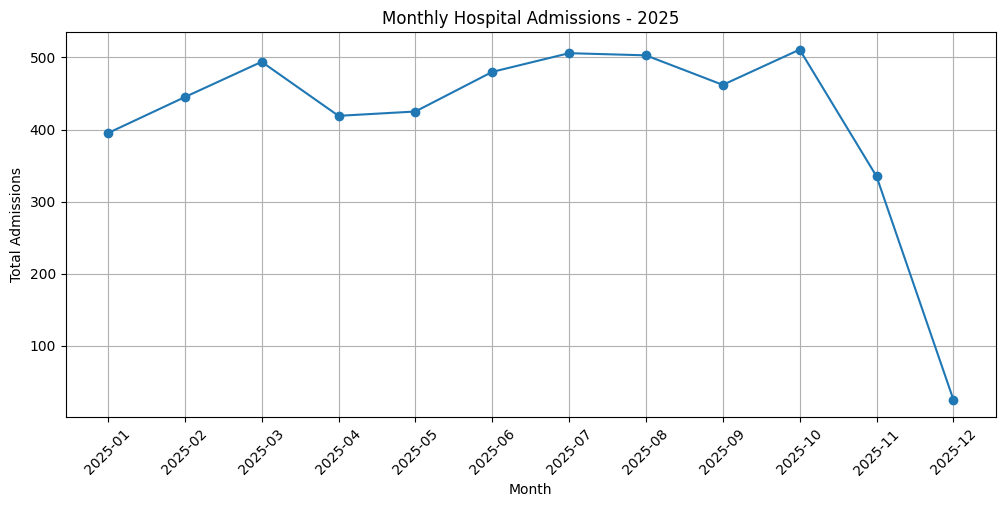

In [33]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_admissions["Admission_Month"],
    monthly_admissions["Total_Admissions"],
    marker="o"
)

plt.title("Monthly Hospital Admissions - 2025")
plt.xlabel("Month")
plt.ylabel("Total Admissions")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

In [34]:
print(monthly_admissions)

print("\nLast Admission Date:")
print(patient_df["Admission_Date"].max())

department_admissions = (
    patient_df["Department"]
    .value_counts()
    .reset_index()
)

department_admissions.columns = [
    "Department",
    "Total_Admissions"
]

display(department_admissions)

   Admission_Month  Total_Admissions
0          2025-01               395
1          2025-02               445
2          2025-03               494
3          2025-04               419
4          2025-05               425
5          2025-06               480
6          2025-07               506
7          2025-08               503
8          2025-09               462
9          2025-10               511
10         2025-11               335
11         2025-12                25

Last Admission Date:
2025-12-20 00:00:00


,Department,Total_Admissions
0,Cardiology,1427
1,Neurology,1320
2,Emergency,938
3,General Medicine,669
4,Orthopedics,646


**BAR Chart**

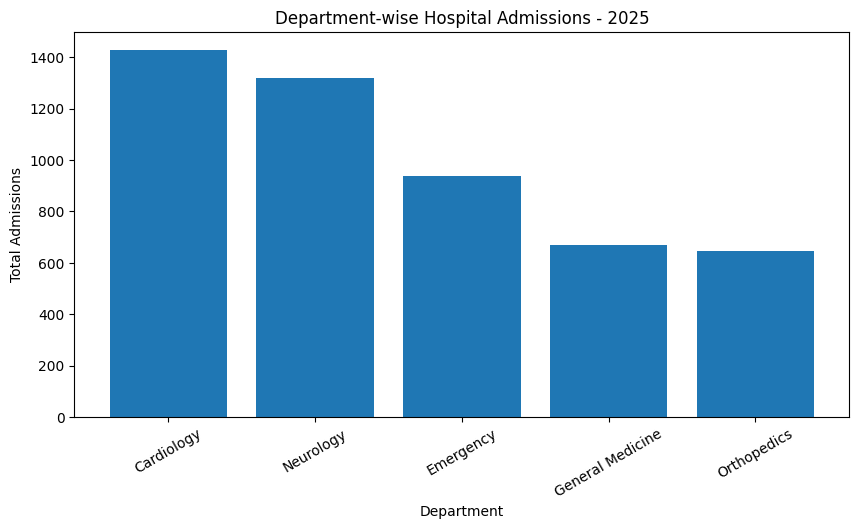

In [35]:
plt.figure(figsize=(10, 5))

plt.bar(
    department_admissions["Department"],
    department_admissions["Total_Admissions"]
)

plt.title("Department-wise Hospital Admissions - 2025")
plt.xlabel("Department")
plt.ylabel("Total Admissions")
plt.xticks(rotation=30)
plt.show()

Average Length of Stay (ALOS)
ALOS measures the average number of days patients stay in the hospital.

Formula:
*ALOS=\frac {Total Patient Stay Days}{Total Admissions}*

For this project, we'll use the Length_of_Stay_Days column.

In [36]:
overall_alos = patient_df["Length_of_Stay_Days"].mean()

print("Overall Average Length of Stay:",
      round(overall_alos, 2), "days")

department_alos = (
    patient_df.groupby("Department")["Length_of_Stay_Days"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

display(department_alos)

Overall Average Length of Stay: 3.53 days


,Length_of_Stay_Days
Department,
Emergency,3.57
Cardiology,3.56
Orthopedics,3.53
General Medicine,3.52
Neurology,3.49


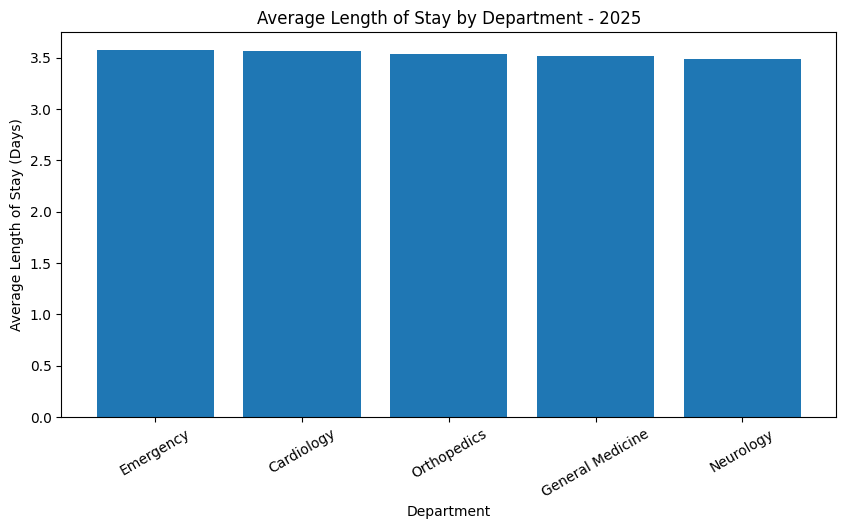

In [37]:
plt.figure(figsize=(10, 5))

plt.bar(
    department_alos.index,
    department_alos.values
)

plt.title("Average Length of Stay by Department - 2025")
plt.xlabel("Department")
plt.ylabel("Average Length of Stay (Days)")
plt.xticks(rotation=30)
plt.show()

**Department	  &     Approx. ALOS**

Emergency	         - 3.57 days

Cardiology	    -  3.56 days

Orthopedics	  -    3.54 days

General Medicine -	3.52 days

Neurology	      -  3.49 days

In [38]:
overall_bor = (
    bed_df["Occupied_Beds"].sum()
    / bed_df["Total_Beds"].sum()
) * 100

print("Overall Bed Occupancy Rate:",
      round(overall_bor, 2), "%")

Overall Bed Occupancy Rate: 27.2 %


In [39]:
department_bor = (
    bed_df.groupby("Department")
    .agg(
        Total_Occupied=("Occupied_Beds", "sum"),
        Total_Capacity=("Total_Beds", "sum")
    )
)

department_bor["Occupancy_Rate"] = (
    department_bor["Total_Occupied"]
    / department_bor["Total_Capacity"]
) * 100

department_bor["Occupancy_Rate"] = (
    department_bor["Occupancy_Rate"].round(2)
)

display(department_bor)

,Total_Occupied,Total_Capacity,Occupancy_Rate
Department,,,
Cardiology,5076,19710,25.75
Emergency,3345,10950,30.55
General Medicine,2352,7300,32.22
Neurology,4613,19710,23.40
Orthopedics,2283,7300,31.27


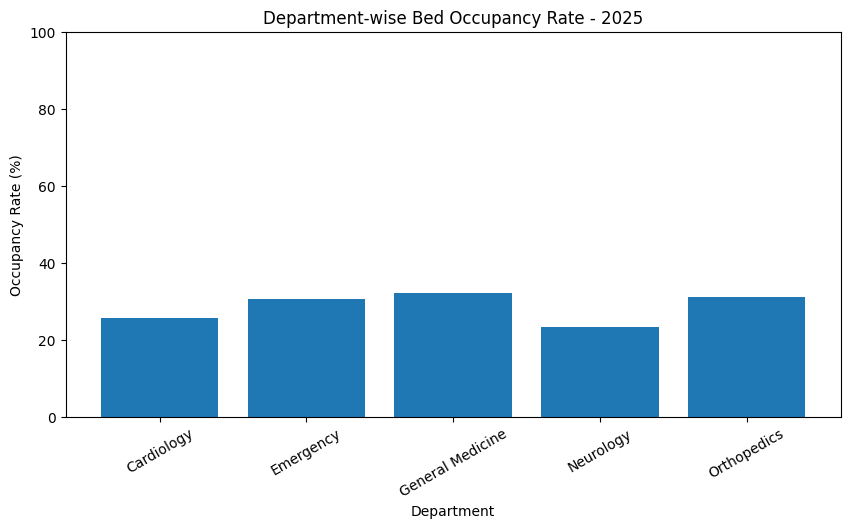

In [40]:
plt.figure(figsize=(10, 5))

plt.bar(
    department_bor.index,
    department_bor["Occupancy_Rate"]
)

plt.title("Department-wise Bed Occupancy Rate - 2025")
plt.xlabel("Department")
plt.ylabel("Occupancy Rate (%)")
plt.xticks(rotation=30)
plt.ylim(0, 100)
plt.show()

**Department-wise Waiting Time**

In [41]:
department_wait = (
    patient_df.groupby("Department")["Waiting_Time_Minutes"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

display(department_wait)

,Waiting_Time_Minutes
Department,
Emergency,76.36
Orthopedics,41.15
General Medicine,40.55
Cardiology,40.25
Neurology,39.68


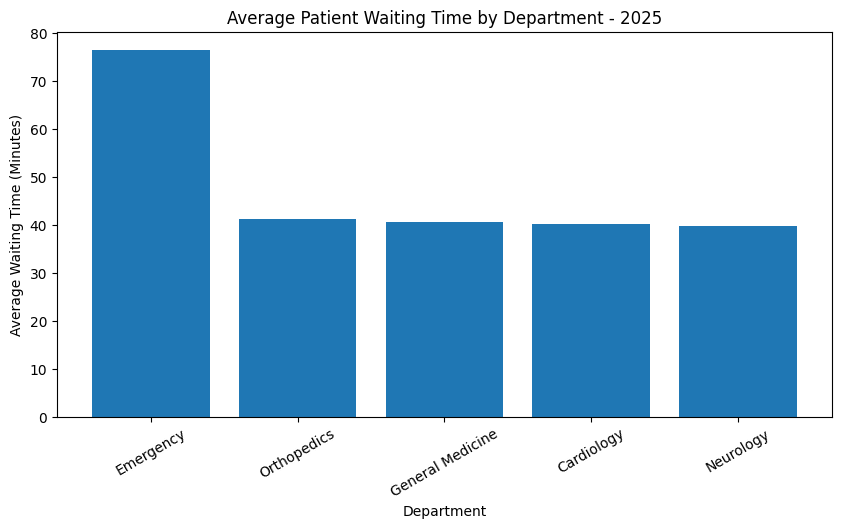

In [42]:
plt.figure(figsize=(10, 5))

plt.bar(
    department_wait.index,
    department_wait.values
)

plt.title("Average Patient Waiting Time by Department - 2025")
plt.xlabel("Department")
plt.ylabel("Average Waiting Time (Minutes)")
plt.xticks(rotation=30)
plt.show()

In [43]:
shift_wait = (
    patient_df.groupby("Shift")["Waiting_Time_Minutes"]
    .mean()
    .round(2)
    .sort_values(ascending=False)
)

display(shift_wait)

,Waiting_Time_Minutes
Shift,
Evening,47.15
Morning,46.92


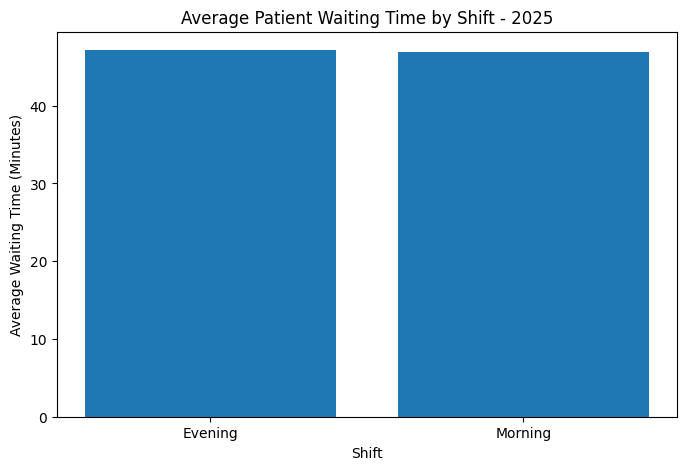

In [44]:
plt.figure(figsize=(8, 5))

plt.bar(
    shift_wait.index,
    shift_wait.values
)

plt.title("Average Patient Waiting Time by Shift - 2025")
plt.xlabel("Shift")
plt.ylabel("Average Waiting Time (Minutes)")
plt.show()

**Staff Availability Analysis**

We want to answer: *Which department has the highest staff availability, and which shift has the most absences?*

In [46]:
staff_df = staff_schedule_df.copy()

department_staff = (
    staff_df.groupby("Department")["Availability"]
    .value_counts(normalize=True)
    .mul(100)
    .unstack(fill_value=0)
    .round(2)
)

display(department_staff)

Availability,Absent,Available
Department,,
Cardiology,5.55,94.45
Emergency,6.02,93.98
General Medicine,5.62,94.38
Neurology,5.71,94.29
Orthopedics,6.42,93.58


In [47]:
shift_staff = (
    staff_df.groupby("Shift")["Availability"]
    .value_counts(normalize=True)
    .mul(100)
    .unstack(fill_value=0)
    .round(2)
)

display(shift_staff)

Availability,Absent,Available
Shift,,
Evening,5.73,94.27
Morning,6.01,93.99
Night,5.86,94.14


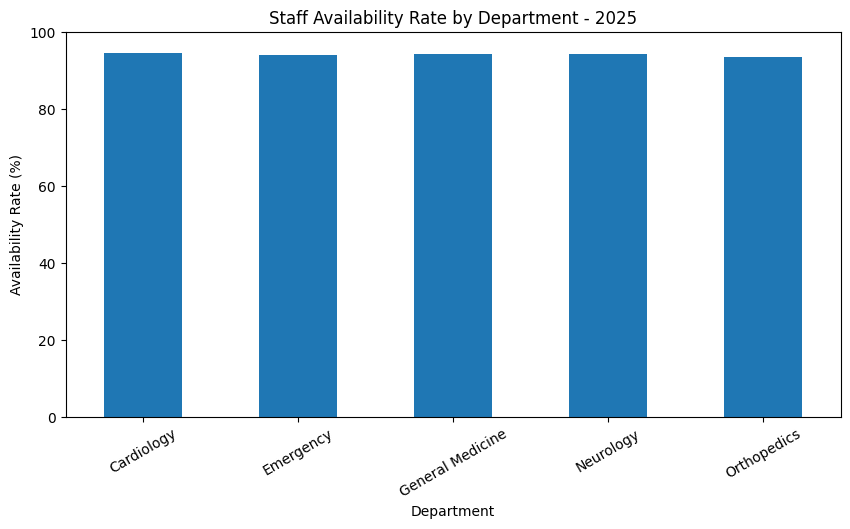

In [48]:
department_staff["Available"].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Staff Availability Rate by Department - 2025")
plt.xlabel("Department")
plt.ylabel("Availability Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=30)
plt.show()

**Final KPI Summary**

In [49]:
total_admissions = len(patient_df)

unique_patients = patient_df["Patient_ID"].nunique()

avg_los = patient_df["Length_of_Stay_Days"].mean()

avg_wait = patient_df["Waiting_Time_Minutes"].mean()

bed_occupancy = (
    bed_df["Occupied_Beds"].sum()
    / bed_df["Total_Beds"].sum()
) * 100

staff_availability = (
    staff_df["Availability"].eq("Available").mean()
) * 100

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Admissions",
        "Unique Patients",
        "Average Length of Stay (Days)",
        "Average Waiting Time (Minutes)",
        "Bed Occupancy Rate (%)",
        "Staff Availability Rate (%)"
    ],
    "Value": [
        total_admissions,
        unique_patients,
        round(avg_los, 2),
        round(avg_wait, 2),
        round(bed_occupancy, 2),
        round(staff_availability, 2)
    ]
})

display(kpi_summary)

,KPI,Value
0,Total Admissions,5000.00
1,Unique Patients,4400.00
2,Average Length of Stay (Days),3.53
3,Average Waiting Time (Minutes),47.03
4,Bed Occupancy Rate (%),27.20
5,Staff Availability Rate (%),94.14


In [50]:
kpi_summary.to_csv(
    "Healthcare_KPI_Summary.csv",
    index=False
)

files.download("Healthcare_KPI_Summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:
staff_df.to_csv(
    "Staff_Schedule_Merged.csv",
    index=False
)

files.download("Staff_Schedule_Merged.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>